In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/bhavikjikadara/fake-news-detection/fake.csv
/kaggle/input/datasets/bhavikjikadara/fake-news-detection/true.csv


In [2]:
fake=pd.read_csv(r"/kaggle/input/datasets/bhavikjikadara/fake-news-detection/fake.csv")
true=pd.read_csv(r"/kaggle/input/datasets/bhavikjikadara/fake-news-detection/true.csv")


In [3]:
fake.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB


In [4]:
true.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


In [5]:
true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [6]:
fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [7]:
fake["subject"].value_counts()

subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

In [8]:
true["subject"].value_counts()

subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64

In [9]:
fake.isnull()

,title,text,subject,date
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
23476,False,False,False,False
23477,False,False,False,False
23478,False,False,False,False
23479,False,False,False,False


In [10]:
true.isnull()

,title,text,subject,date
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
21412,False,False,False,False
21413,False,False,False,False
21414,False,False,False,False
21415,False,False,False,False


In [11]:
##creating a category for fake and true for matching whether news is fake or not.
fake["category"]=1;
true["category"]=0;
print("Category added")

Category added


In [12]:
##concatenating for creating one training dataset for the model 
##shuffle(reset index): Because fake news records might originally appear first and true news records afterward. 
#Shuffling mixes them randomly and avoids unwanted ordering during training.

training_ds=pd.concat([fake,true])
training_ds=training_ds.sample(frac=1).reset_index(drop=True);
training_ds.info()
training_ds.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   title     44898 non-null  object
 1   text      44898 non-null  object
 2   subject   44898 non-null  object
 3   date      44898 non-null  object
 4   category  44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB


,title,text,subject,date,category
0,Grace Mugabe returns to Zimbabwe campaign trai...,HARARE (Reuters) - Zimbabwe s first lady Grace...,worldnews,"September 1, 2017",0
1,Obama Eyeing Digital Media Career Post-Presid...,Before Donald Trump pulled off winning the pre...,News,"December 3, 2016",1
2,BREAKING: CLINTON FOUNDATION FINDS $26 MILLION...,The Clintons found more money $26 million more...,politics,"May 22, 2015",1
3,UK PM May postpones trip to China to avoid tim...,LONDON (Reuters) - British Prime Minister Ther...,worldnews,"October 6, 2017",0
4,Trump discusses immigration ideas in dinner wi...,WASHINGTON (Reuters) - President Donald Trump ...,politicsNews,"October 3, 2017",0


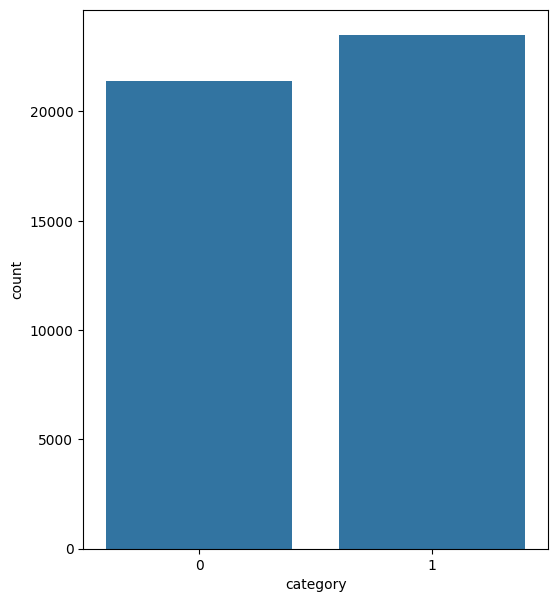

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(6,7))
sns.countplot(x=training_ds["category"])
plt.show()



<Axes: xlabel='subject', ylabel='count'>

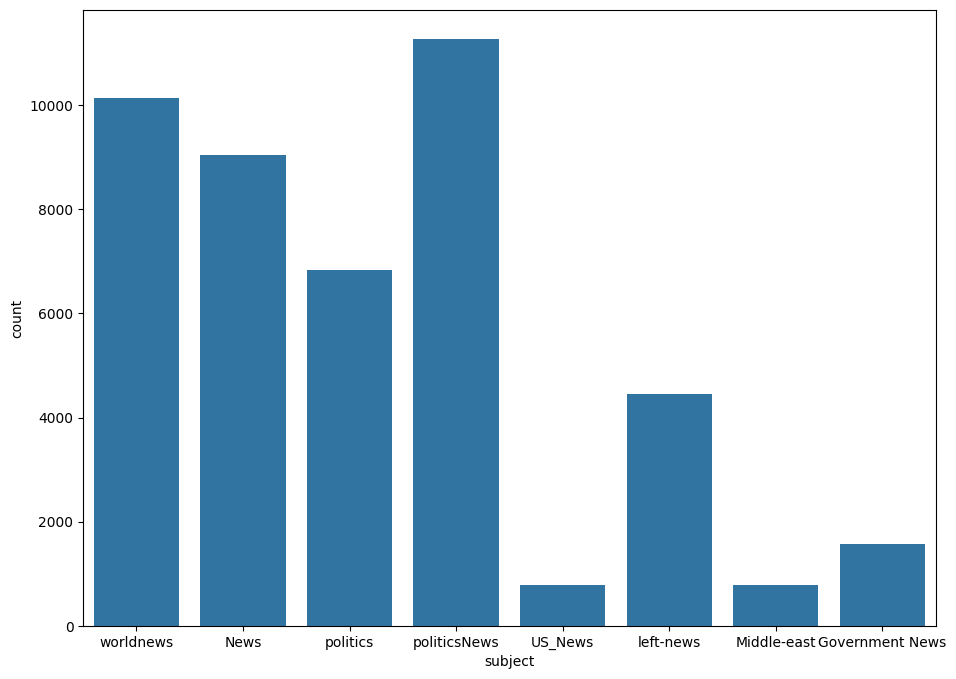

In [14]:
plt.figure(figsize=(11,8))
sns.countplot(x=training_ds["subject"])


In [15]:
##Drop unnecessary columns and retain the useful columns
training_ds=training_ds[["text","category"]]
training_ds.head()

,text,category
0,HARARE (Reuters) - Zimbabwe s first lady Grace...,0
1,Before Donald Trump pulled off winning the pre...,1
2,The Clintons found more money $26 million more...,1
3,LONDON (Reuters) - British Prime Minister Ther...,0
4,WASHINGTON (Reuters) - President Donald Trump ...,0


In [16]:
##DATA CLEANING

In [17]:
##Check if any text is only whitespace

blanks=[]

for index,text in training_ds["text"].items():
    if(text.isspace()):
        blanks.append(index);

print(len(blanks))

631


In [18]:
training_ds.shape

(44898, 2)

In [19]:
training_ds.drop(blanks,inplace=True)
training_ds.shape

(44267, 2)

In [20]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import spacy
import re
nlp=spacy.load("en_core_web_sm")

In [21]:
lemma=WordNetLemmatizer()

In [22]:
##stopwords of spacy
list1=nlp.Defaults.stop_words

#stopwords of nltk
list2=stopwords.words("english")

Stopwords=set(set(list1)|set(list2));

print(len(Stopwords))


401


In [23]:
##Cleaning text
def clean_text(text):

    s="";
    text=text.lower();
    text=re.sub(r"i'm","i am",text);
    text=re.sub(r"he's","he is",text);
    text=re.sub(r"she's","she is",text);
    text=re.sub(r"would'nt","would not",text);
    text=re.sub(r"won't","will not",text);
    text=re.sub(r"can't","cannot",text);
    text=re.sub(r"are'nt","are not",text);
    text=re.sub(r"\'ll","will",text);
    text=re.sub(r"\'ve","have",text);
    text=re.sub(r"\'re","are",text);
    text=re.sub(r"\'d","would",text);
    text=re.sub(r"\'s","is",text);
    text=re.sub(r"[`~!@#$%^&*()_+=-{}[]:;?/<>,.|\]"," ",text)
    ##whitespaces
    text=re.sub(r"\s+"," ",text)
    #any character other than this
    text=re.sub("[^A-Za-z0-9]+"," ",text)
    for word in text.split():
        if word not in Stopwords:
            s+=lemma.lemmatize(word)+" ";

    return s


    



In [24]:
training_ds["text"][10]

'It happened again. One would assume that after Monday s debacle when the RNC displayed a white supremacist s tweet on a marquee scrolling around the building, they would check what they put up there. On the third night of the GOP convention, a tweet from white power organization VDARE heaped praise on Republicans for getting the  crowd fired up against illegal immigration.  On Thursday, the GOP gave voice to yet another white supremacist, this time (appropriately) during Donald Trump s speech.The most recent tweet was written by the account @Western_Triumph, whose profile description is loaded with a number of alarming hashtags, including #ProWhite, #RaceRealist, #SlayCulturalMarxism, #LoveYourRace, and #Trump2016. On the big screen in the Quicken Loans Arena about midway through Trump s acceptance speech,  Western Triumph  quoted The Donald and added that  It s time to start WINNING again!  The hashtag #TrumpIsWithYou was added for effect, likely because there is a sentiment in the w

In [25]:
clean_text(training_ds["text"][10])

'happened assume monday debacle rnc displayed white supremacist tweet marquee scrolling building check night gop convention tweet white power organization vdare heaped praise republican getting crowd fired illegal immigration thursday gop gave voice white supremacist time appropriately donald trump speech recent tweet written account western triumph profile description loaded number alarming hashtags including prowhite racerealist slayculturalmarxism loveyourrace trump2016 big screen quicken loan arena midway trump acceptance speech western triumph quoted donald added time start winning hashtag trumpiswithyou added effect likely sentiment white nationalist community trump running tweet screen loop rncincle check account pic twitter com 9kgpzblrlk andy aplikowski aaarf july 22 2016here tweet account lesdoggg typical entitled black woman dish plenty hate white cry racist hit freemilo western triumph western triumph july 20 2016so ugly talentless sheboon ghostbusters went cry jack twitter

In [26]:
##clean whole text

training_ds["text"]=training_ds["text"].apply(clean_text);

In [27]:
training_ds["text"].head()

0    harare reuters zimbabwe lady grace mugabe hit ...
1    donald trump pulled winning presidency saw com...
2    clinton found money 26 million position govern...
3    london reuters british prime minister theresa ...
4    washington reuters president donald trump disc...
Name: text, dtype: object

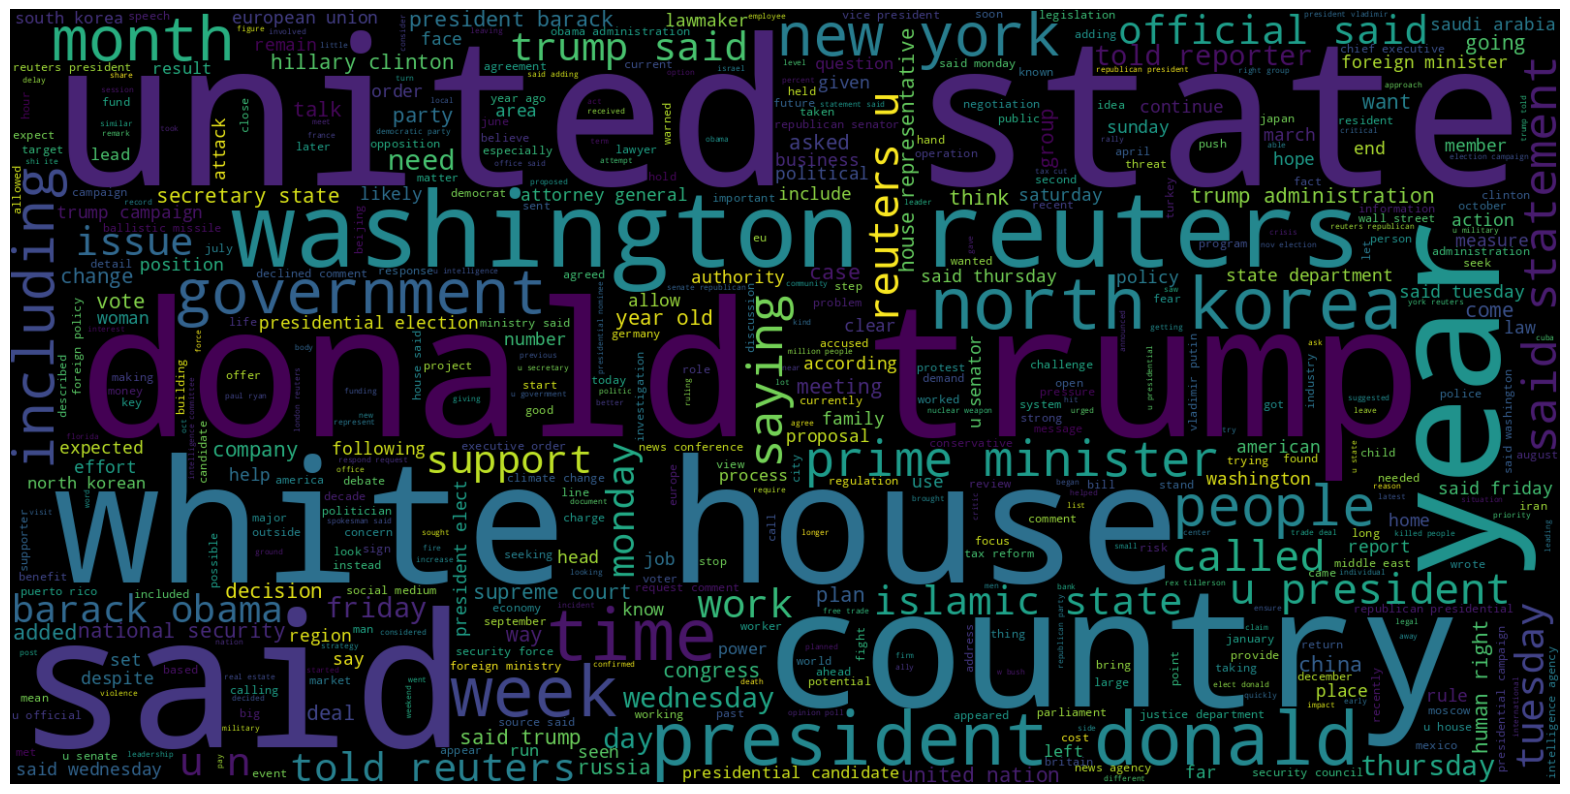

In [28]:
from wordcloud import WordCloud

plt.figure(figsize=(20,20));
Wc=WordCloud(max_words=500,width=1600,height=800).generate(" ".join(training_ds[training_ds.category==0].text))
#remove axis
plt.axis("off")
#display,interpolation for smoother img
plt.imshow(Wc,interpolation="bilinear")

In [29]:
##MODEL BUILDING

In [30]:
from sklearn.model_selection import train_test_split

X=training_ds["text"];
Y=training_ds["category"];

X_train,X_test,Y_train,Y_test=train_test_split(X,Y,random_state=42);

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer=TfidfVectorizer();
X_train_tfidf=vectorizer.fit_transform(X_train)

In [32]:
X_train_tfidf

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4956207 stored elements and shape (33200, 100591)>

In [33]:
from sklearn.svm import LinearSVC

clf=LinearSVC()
clf.fit(X_train_tfidf,Y_train)

LinearSVC()

In [34]:
from sklearn.pipeline import Pipeline

text_clf = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LinearSVC())
])

text_clf.fit(X_train, Y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer()), ('clf', LinearSVC())])

In [35]:
predictions=text_clf.predict(X_test)

In [36]:
from sklearn.metrics import classification_report,confusion_matrix
print(classification_report(Y_test,predictions))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      5360
           1       0.99      0.99      0.99      5707

    accuracy                           0.99     11067
   macro avg       0.99      0.99      0.99     11067
weighted avg       0.99      0.99      0.99     11067



In [37]:
print(confusion_matrix(Y_test,predictions))

[[5317   43]
 [  38 5669]]
